In [1]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:3 https://cli.github.com/packages stable/main amd64 Packages [358 B]
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [2,066 kB]
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Get:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:7 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:8 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:9 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [81.1 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:13 https://r2u.stat.illinois.edu/ubuntu noble/main 

In [2]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Writing main.cpp


In [3]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [4]:
import cv2
import numpy as np
import os

# Eğer hafta9resim.jpg veya benzer uzantılı dosya yoksa, test amaçlı örnek bir insan teni içeren görsel oluşturuyoruz
image_path = 'hafta9resim.jpg'
if not os.path.exists(image_path):
    # Koyu/açık ten renkleri ve arka plana sahip 400x400 piksellik sanal bir test görseli oluşturalım
    dummy_img = np.zeros((400, 400, 3), dtype=np.uint8)
    # Arka plan mavi (ten dışı)
    dummy_img[:] = [200, 100, 50]
    # Ten rengi taklit eden bölgeler (BGR sırasıyla)
    cv2.rectangle(dummy_img, (50, 50), (200, 200), (120, 150, 200), -1) # Açık ten tonu
    cv2.rectangle(dummy_img, (220, 220), (350, 350), (60, 80, 140), -1)  # Koyu ten tonu
    cv2.imwrite(image_path, dummy_img)
    print("Test için örnek 'hafta9resim.jpg' dosyası oluşturuldu.")
else:
    print("'hafta9resim' dosyası zaten mevcut.")

Test için örnek 'hafta9resim.jpg' dosyası oluşturuldu.


In [5]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>

using namespace cv;
using namespace std;

// RGB (BGR) renk uzayında basit ten rengi tespiti
Mat detectSkinBGR(const Mat& input) {
    Mat result = input.clone();
    for (int r = 0; r < input.rows; r++) {
        for (int c = 0; c < input.cols; c++) {
            Vec3b color = input.at<Vec3b>(r, c);
            uchar B = color[0];
            uchar G = color[1];
            uchar R = color[2];

            // Yaygın RGB ten rengi kuralı:
            // R > 95 ve G > 40 ve B > 20 ve
            // (max(R,G,B) - min(R,G,B)) > 15 ve |R - G| > 15 ve R > G ve R > B
            bool isSkin = (R > 95 && G > 40 && B > 20 &&
                          (max({R, G, B}) - min({R, G, B})) > 15 &&
                          abs(R - G) > 15 && R > G && R > B);

            if (!isSkin) {
                // Ten dışı bölgeleri tam kırmızı yap (BGR formatında B=0, G=0, R=255)
                result.at<Vec3b>(r, c) = Vec3b(0, 0, 255);
            }
        }
    }
    return result;
}

// YCbCr renk uzayında ten rengi tespiti
Mat detectSkinYCbCr(const Mat& input) {
    Mat ycbcr;
    cvtColor(input, ycbcr, COLOR_BGR2YCrCb);
    Mat result = input.clone();

    for (int r = 0; r < input.rows; r++) {
        for (int c = 0; c < input.cols; c++) {
            Vec3b p = ycbcr.at<Vec3b>(r, c);
            uchar Y = p[0];
            uchar Cr = p[1];
            uchar Cb = p[2];

            // Klasik YCbCr ten rengi aralığı:
            // 80 <= Cb <= 120 ve 133 <= Cr <= 173
            bool isSkin = (Cb >= 80 && Cb <= 120 && Cr >= 133 && Cr <= 173);

            if (!isSkin) {
                result.at<Vec3b>(r, c) = Vec3b(0, 0, 255);
            }
        }
    }
    return result;
}

// HSV renk uzayında ten rengi tespiti
Mat detectSkinHSV(const Mat& input) {
    Mat hsv;
    cvtColor(input, hsv, COLOR_BGR2HSV);
    Mat result = input.clone();

    for (int r = 0; r < input.rows; r++) {
        for (int c = 0; c < input.cols; c++) {
            Vec3b p = hsv.at<Vec3b>(r, c);
            float H = p[0]; // Hue (0 - 180)
            float S = p[1]; // Saturation (0 - 255)
            float V = p[2]; // Value (0 - 255)

            // HSV ten rengi aralığı:
            // 0 <= H <= 17 VEYA 170 <= H <= 180 (Kırmızı tonları)
            // 15 <= S <= 170
            bool isSkin = (((H >= 0 && H <= 17) || (H >= 170 && H <= 180)) && S >= 15 && S <= 170);

            if (!isSkin) {
                result.at<Vec3b>(r, c) = Vec3b(0, 0, 255);
            }
        }
    }
    return result;
}

int main() {
    // Farklı olası uzantıları kontrol ederek resmi yükleyelim
    Mat img = imread("hafta9resim.jpg");
    if (img.empty()) {
        img = imread("hafta9resim.png");
    }
    if (img.empty()) {
        cerr << "Hata: hafta9resim bulunamadı! Lütfen resmi yüklediğinizden emin olun." << endl;
        return -1;
    }

    Mat skinRGB = detectSkinBGR(img);
    Mat skinYCbCr = detectSkinYCbCr(img);
    Mat skinHSV = detectSkinHSV(img);

    // Çıktıları kaydet
    imwrite("sonuc_rgb.jpg", skinRGB);
    imwrite("sonuc_ycbcr.jpg", skinYCbCr);
    imwrite("sonuc_hsv.jpg", skinHSV);

    cout << "İşlem tamamlandı! Sonuçlar kaydedildi:" << endl;
    cout << "- sonuc_rgb.jpg" << endl;
    cout << "- sonuc_ycbcr.jpg" << endl;
    cout << "- sonuc_hsv.jpg" << endl;

    return 0;
}

Overwriting main.cpp


In [6]:
# C++ kodunu derle ve çalıştır
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

İşlem tamamlandı! Sonuçlar kaydedildi:
- sonuc_rgb.jpg
- sonuc_ycbcr.jpg
- sonuc_hsv.jpg


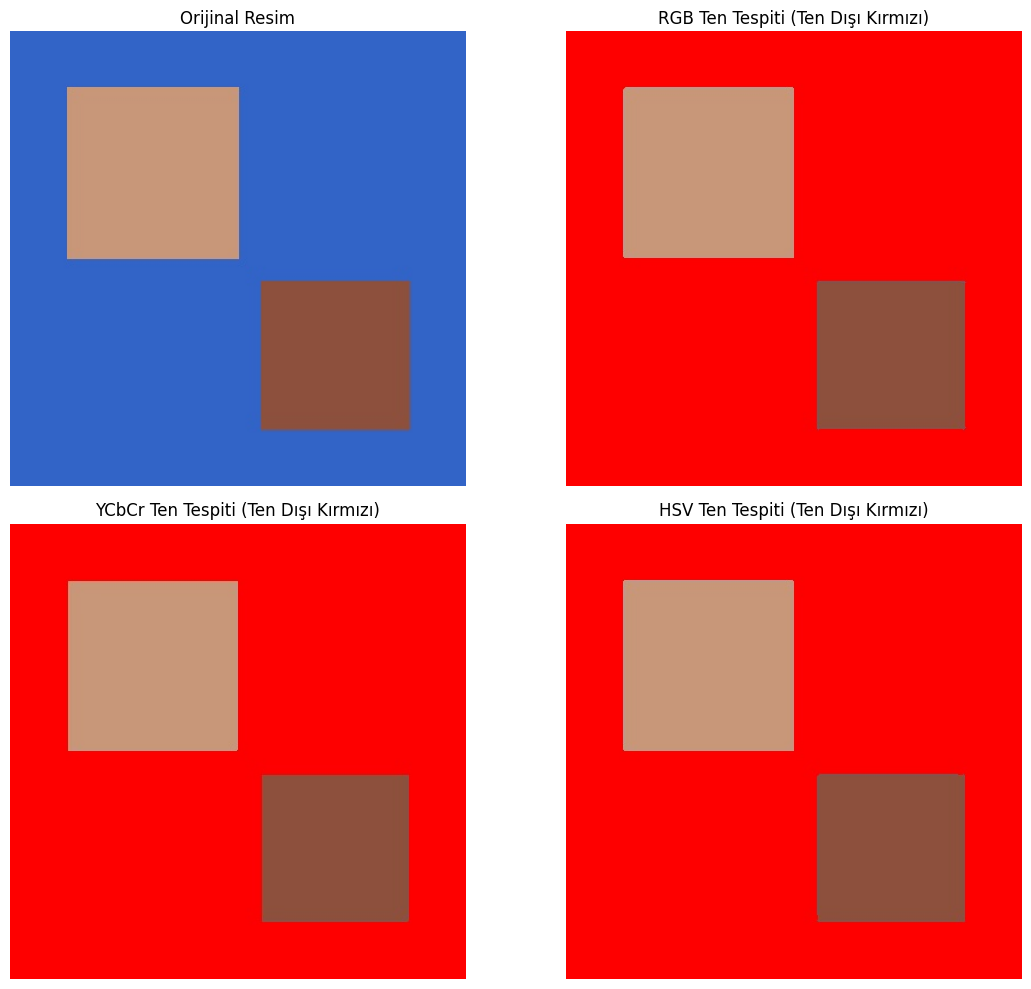

In [7]:
# Sonuçları görselleştirelim
import matplotlib.pyplot as plt

img_org = cv2.imread('hafta9resim.jpg')
img_rgb = cv2.imread('sonuc_rgb.jpg')
img_ycbcr = cv2.imread('sonuc_ycbcr.jpg')
img_hsv = cv2.imread('sonuc_hsv.jpg')

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes[0, 0].imshow(cv2.cvtColor(img_org, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title('Orijinal Resim')
axes[0, 0].axis('off')

axes[0, 1].imshow(cv2.cvtColor(img_rgb, cv2.COLOR_BGR2RGB))
axes[0, 1].set_title('RGB Ten Tespiti (Ten Dışı Kırmızı)')
axes[0, 1].axis('off')

axes[1, 0].imshow(cv2.cvtColor(img_ycbcr, cv2.COLOR_BGR2RGB))
axes[1, 0].set_title('YCbCr Ten Tespiti (Ten Dışı Kırmızı)')
axes[1, 0].axis('off')

axes[1, 1].imshow(cv2.cvtColor(img_hsv, cv2.COLOR_BGR2RGB))
axes[1, 1].set_title('HSV Ten Tespiti (Ten Dışı Kırmızı)')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()